<a href="https://colab.research.google.com/github/tejas2408c/BDS_poster_analysis/blob/main/rainfall_analysis_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Big Data Analysis of Rainfall Patterns and Extreme Rainfall Events in India

**Single-page poster project — analysis first, poster after verified results.**

This notebook loads the IMD-derived Parquet dataset with PySpark and reports its real schema, row count, date coverage, missing values, rainfall summaries, and coordinate coverage. It does not assume the results.

In [ ]:
!pip -q install pyspark

## 1. Upload the dataset

Run this cell and select **`india_rain_daily_2015_2025.parquet`** from your computer. The file found locally is about 41.2 MB. Uploading it to this Colab session makes it available only for this runtime session.

In [ ]:
from google.colab import files
uploaded = files.upload()
parquet_path = next((name for name in uploaded if name.lower().endswith('.parquet')), None)
if parquet_path is None:
    raise FileNotFoundError('Upload the .parquet dataset, then rerun this cell.')
print('Selected file:', parquet_path)

Saving india_rain_daily_2015_2025.parquet to india_rain_daily_2015_2025.parquet
Selected file: india_rain_daily_2015_2025.parquet


In [ ]:
from pyspark.sql import SparkSession, functions as F
spark = (SparkSession.builder.appName('IndiaRainfallAnalysis')
         .config('spark.sql.session.timeZone', 'UTC').getOrCreate())
df = spark.read.parquet(parquet_path)
df.printSchema()
print('Columns:', df.columns)
row_count = df.count()
print(f'Rows: {row_count:,}')
df.show(5, truncate=False)

root
 |-- point: string (nullable = true)
 |-- lat: float (nullable = true)
 |-- lon: float (nullable = true)
 |-- date: date (nullable = true)
 |-- rain_mm: float (nullable = true)

Columns: ['point', 'lat', 'lon', 'date', 'rain_mm']
Rows: 19,945,352
+---------+----+----+----------+---------+
|point    |lat |lon |date      |rain_mm  |
+---------+----+----+----------+---------+
|8.25_77.0|8.25|77.0|2015-01-01|10.442368|
|8.25_77.0|8.25|77.0|2015-01-02|0.0      |
|8.25_77.0|8.25|77.0|2015-01-03|0.0      |
|8.25_77.0|8.25|77.0|2015-01-04|0.0      |
|8.25_77.0|8.25|77.0|2015-01-05|0.0      |
+---------+----+----+----------+---------+
only showing top 5 rows


## 2. Identify date, rainfall, and coordinate fields

The next cell prints field names and types and suggests likely columns using their names. Check those suggestions against the schema and sample rows. If a suggestion is wrong, set the corresponding variable manually before running the summary cells.

In [ ]:
fields = [(f.name, f.dataType.simpleString()) for f in df.schema.fields]
print('Field names and types:', fields)
def suggest(patterns):
    return next((name for name in df.columns if any(p in name.lower() for p in patterns)), None)
date_col = suggest(['date', 'time', 'day'])
rain_col = suggest(['rain', 'precip', 'prcp'])
lat_col = suggest(['latitude', 'lat'])
lon_col = suggest(['longitude', 'lon', 'long'])
print('Suggested fields — date:', date_col, '| rainfall:', rain_col, '| latitude:', lat_col, '| longitude:', lon_col)
# If needed, replace the values above with exact names from the printed schema, e.g. date_col = 'DATE'

Field names and types: [('point', 'string'), ('lat', 'float'), ('lon', 'float'), ('date', 'date'), ('rain_mm', 'float')]
Suggested fields — date: date | rainfall: rain_mm | latitude: lat | longitude: lon


In [ ]:
# Missing values: null and NaN counts for every field
null_counts = df.select([
    F.sum(F.when(F.col(c).isNull() | (F.isnan(c) if dict(fields)[c] in ('float', 'double') else F.lit(False)), 1).otherwise(0)).alias(c)
    for c in df.columns
]).first().asDict()
print('Missing values by field:', {k: int(v or 0) for k, v in null_counts.items()})

Missing values by field: {'point': 0, 'lat': 0, 'lon': 0, 'date': 0, 'rain_mm': 79}


In [ ]:
# Date coverage; supports Spark date/timestamp columns and common date strings
if date_col:
    date_type = dict(fields)[date_col]
    parsed_date = F.to_date(F.col(date_col))
    date_stats = df.select(F.min(parsed_date).alias('earliest_date'), F.max(parsed_date).alias('latest_date'), F.sum(F.when(parsed_date.isNull(), 1).otherwise(0)).alias('unparsed_or_missing_dates')).first()
    print('Date coverage:', date_stats.asDict())
else:
    print('No date field was suggested. Set date_col to the date field shown in the schema.')

Date coverage: {'earliest_date': datetime.date(2015, 1, 1), 'latest_date': datetime.date(2025, 12, 31), 'unparsed_or_missing_dates': 0}


In [ ]:
# Rainfall values: valid/negative counts and descriptive statistics
if rain_col:
    rainfall = F.col(rain_col).cast('double')
    print('Rainfall statistics (source units):')
    df.select(F.count(rainfall).alias('non_null'), F.sum(F.when(rainfall < 0, 1).otherwise(0)).alias('negative_values'), F.min(rainfall).alias('minimum'), F.expr(f'percentile_approx(`{rain_col}`, 0.5)').alias('median_approx'), F.avg(rainfall).alias('mean'), F.expr(f'percentile_approx(`{rain_col}`, 0.95)').alias('p95_approx'), F.max(rainfall).alias('maximum')).show(truncate=False)
    df.groupBy(rainfall.alias('rainfall_value')).count().orderBy(F.desc('count')).show(20, truncate=False)
else:
    print('No rainfall field was suggested. Set rain_col to the rainfall field shown in the schema.')

Rainfall statistics (source units):
+--------+---------------+-------+-------------+-----------------+----------+----------------+
|non_null|negative_values|minimum|median_approx|mean             |p95_approx|maximum         |
+--------+---------------+-------+-------------+-----------------+----------+----------------+
|19945273|0              |0.0    |0.0          |3.211473678240238|19.027348 |979.144775390625|
+--------+---------------+-------+-------------+-----------------+----------+----------------+

+-------------------+--------+
|rainfall_value     |count   |
+-------------------+--------+
|0.0                |14184704|
|1.0                |2160    |
|2.0                |1870    |
|0.20000000298023224|1368    |
|1.2000000476837158 |1237    |
|0.6000000238418579 |1110    |
|0.4000000059604645 |1086    |
|3.0                |1031    |
|0.800000011920929  |868     |
|4.0                |854     |
|5.0                |800     |
|2.200000047683716  |659     |
|1.600000023841858  |61

In [ ]:
# Coordinate coverage (ranges and missing counts)
coord_exprs = []
for label, col_name in [('latitude', lat_col), ('longitude', lon_col)]:
    if col_name:
        value = F.col(col_name).cast('double')
        coord_exprs.extend([F.min(value).alias(f'{label}_min'), F.max(value).alias(f'{label}_max'), F.sum(F.when(value.isNull(), 1).otherwise(0)).alias(f'{label}_missing')])
if coord_exprs:
    df.select(*coord_exprs).show(truncate=False)
else:
    print('Coordinate fields were not both detected. Set lat_col and lon_col from the schema if available.')

+------------+------------+----------------+-------------+-------------+-----------------+
|latitude_min|latitude_max|latitude_missing|longitude_min|longitude_max|longitude_missing|
+------------+------------+----------------+-------------+-------------+-----------------+
|8.25        |37.25       |0               |68.0         |97.25        |0                |
+------------+------------+----------------+-------------+-------------+-----------------+



In [ ]:
df.select(
    F.min("date").alias("first_date"),
    F.max("date").alias("last_date"),
    F.min("lat").alias("min_lat"),
    F.max("lat").alias("max_lat"),
    F.min("lon").alias("min_lon"),
    F.max("lon").alias("max_lon"),
    F.count("rain_mm").alias("rainfall_non_null"),
    F.sum(F.col("rain_mm").isNull().cast("int")).alias("rainfall_null"),
    F.avg("rain_mm").alias("rainfall_mean_mm"),
    F.expr("percentile_approx(rain_mm, 0.95)").alias("rainfall_p95_mm"),
    F.max("rain_mm").alias("rainfall_max_mm")
).show(truncate=False)

+----------+----------+-------+-------+-------+-------+-----------------+-------------+-----------------+---------------+---------------+
|first_date|last_date |min_lat|max_lat|min_lon|max_lon|rainfall_non_null|rainfall_null|rainfall_mean_mm |rainfall_p95_mm|rainfall_max_mm|
+----------+----------+-------+-------+-------+-------+-----------------+-------------+-----------------+---------------+---------------+
|2015-01-01|2025-12-31|8.25   |37.25  |68.0   |97.25  |19945273         |79           |3.211473678240238|19.027348      |979.1448       |
+----------+----------+-------+-------+-------+-------+-----------------+-------------+-----------------+---------------+---------------+



In [ ]:
df.select("date", "point", "lat", "lon", "rain_mm") \
  .orderBy(F.desc("rain_mm")) \
  .show(20, truncate=False)

+----------+-----------+-----+-----+---------+
|date      |point      |lat  |lon  |rain_mm  |
+----------+-----------+-----+-----+---------+
|2022-06-17|25.25_91.25|25.25|91.25|979.1448 |
|2022-06-17|25.25_90.75|25.25|90.75|921.06024|
|2022-06-17|25.25_91.0 |25.25|91.0 |919.2818 |
|2022-06-17|25.5_90.75 |25.5 |90.75|896.8605 |
|2022-06-17|25.25_91.5 |25.25|91.5 |891.51355|
|2022-06-17|25.5_91.0  |25.5 |91.0 |862.294  |
|2022-06-15|25.25_91.5 |25.25|91.5 |779.4168 |
|2022-06-15|25.25_90.75|25.25|90.75|753.8718 |
|2022-06-17|25.5_91.25 |25.5 |91.25|751.1011 |
|2022-06-15|25.25_91.25|25.25|91.25|747.5472 |
|2022-06-15|25.25_91.0 |25.25|91.0 |734.2404 |
|2022-06-15|25.5_90.75 |25.5 |90.75|729.31055|
|2022-06-15|25.5_91.0  |25.5 |91.0 |699.05896|
|2023-12-18|8.5_78.0   |8.5  |78.0 |689.03723|
|2015-08-19|25.25_91.25|25.25|91.25|679.2213 |
|2016-05-28|21.25_81.25|21.25|81.25|673.7085 |
|2016-05-27|21.25_81.25|21.25|81.25|672.9727 |
|2022-06-16|25.25_91.25|25.25|91.25|669.99207|
|2024-06-18|2

In [ ]:
event_area = (
    df.filter(
        (F.col("date").between("2022-06-14", "2022-06-18")) &
        (F.col("lat").between(24.75, 25.75)) &
        (F.col("lon").between(90.5, 91.75))
    )
)

event_area.groupBy("date").agg(
    F.count("*").alias("grid_points"),
    F.avg("rain_mm").alias("mean_rain_mm"),
    F.max("rain_mm").alias("max_rain_mm")
).orderBy("date").show(truncate=False)

+----------+-----------+------------------+-----------+
|date      |grid_points|mean_rain_mm      |max_rain_mm|
+----------+-----------+------------------+-----------+
|2022-06-14|18         |38.924065854814316|81.137955  |
|2022-06-15|18         |381.58078299628363|779.4168   |
|2022-06-16|18         |325.3788886600071 |669.99207  |
|2022-06-17|18         |476.0266015794542 |979.1448   |
|2022-06-18|18         |75.80539141760931 |125.04991  |
+----------+-----------+------------------+-----------+



In [ ]:
df.groupBy(F.month("date").alias("month")).agg(
    F.count("rain_mm").alias("observations"),
    F.avg("rain_mm").alias("mean_rain_mm"),
    F.expr("percentile_approx(rain_mm, 0.5)").alias("median_rain_mm"),
    F.expr("percentile_approx(rain_mm, 0.95)").alias("p95_rain_mm")
).orderBy("month").show(truncate=False)

+-----+------------+------------------+--------------+-----------+
|month|observations|mean_rain_mm      |median_rain_mm|p95_rain_mm|
+-----+------------+------------------+--------------+-----------+
|1    |1692724     |0.4911865043101099|0.0           |1.5932434  |
|2    |1543804     |0.5208742159314796|0.0           |1.6657163  |
|3    |1692724     |0.8810470769799232|0.0           |4.9039097  |
|4    |1638120     |1.4436674779934464|0.0           |8.8        |
|5    |1692724     |2.5194640409745395|0.0           |14.75003   |
|6    |1638120     |5.5074652356256095|0.0           |28.995579  |
|7    |1692724     |9.289170046629321 |1.7006084     |42.728733  |
|8    |1692724     |7.879173627689494 |1.0118976     |37.339153  |
|9    |1638120     |5.975543367556918 |0.117120646   |30.813845  |
|10   |1692645     |2.4777904608902563|0.0           |15.2147665 |
|11   |1638120     |0.8443455770540722|0.0           |2.822227   |
|12   |1692724     |0.5010554405755447|0.0           |0.549301

In [ ]:
df.groupBy(F.year("date").alias("year")).agg(
    F.count("rain_mm").alias("observations"),
    F.avg("rain_mm").alias("mean_rain_mm"),
    F.expr("percentile_approx(rain_mm, 0.95)").alias("p95_rain_mm")
).orderBy("year").show(truncate=False)

+----+------------+------------------+-----------+
|year|observations|mean_rain_mm      |p95_rain_mm|
+----+------------+------------------+-----------+
|2015|1811860     |2.945695444163467 |17.49622   |
|2016|1816824     |3.0025002260230416|18.067389  |
|2017|1811860     |3.0977737317678518|18.5879    |
|2018|1811860     |2.7578841886426435|16.78485   |
|2019|1811860     |3.4766798644445394|20.158512  |
|2020|1816824     |3.487696221255663 |20.169168  |
|2021|1811860     |3.356478264494965 |19.65288   |
|2022|1811860     |3.4443228349751633|20.507065  |
|2023|1811781     |2.9621636890285026|17.470493  |
|2024|1816824     |3.3205582286400572|19.564445  |
|2025|1811860     |3.4739637910253953|20.5564    |
+----+------------+------------------+-----------+



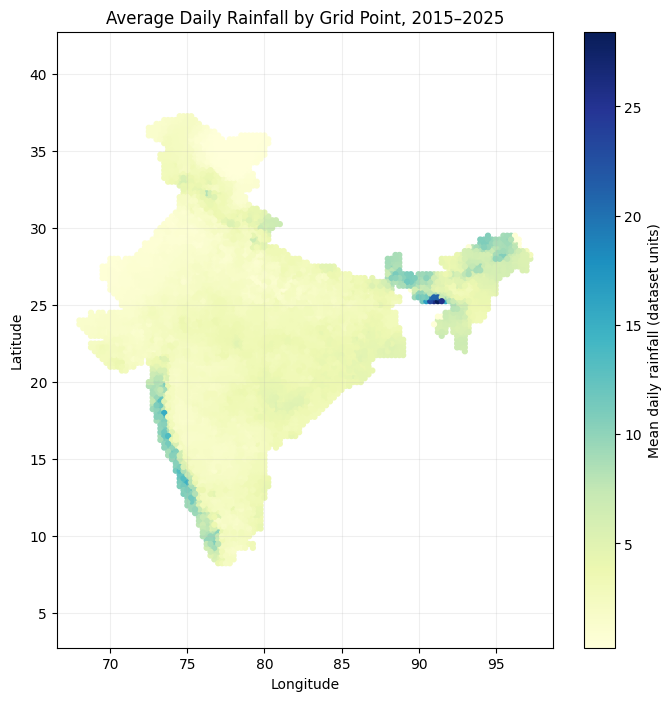

Grid points plotted: 4964


In [ ]:
import matplotlib.pyplot as plt

point_means = (
    df.groupBy("lat", "lon")
      .agg(F.avg("rain_mm").alias("mean_rain_mm"))
      .dropna()
      .toPandas()
)

plt.figure(figsize=(8, 8))
points = plt.scatter(
    point_means["lon"],
    point_means["lat"],
    c=point_means["mean_rain_mm"],
    cmap="YlGnBu",
    s=12
)
plt.colorbar(points, label="Mean daily rainfall (dataset units)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Average Daily Rainfall by Grid Point, 2015–2025")
plt.axis("equal")
plt.grid(alpha=0.2)
plt.show()

print("Grid points plotted:", len(point_means))

## 3. Record provenance and limitations

Before interpreting results, record the dataset's download/source page, exact file name, retrieval date, and any documentation that defines the rainfall units, spatial resolution, and coverage. The file is described in the project conversation as IMD-derived; that description alone does not establish provenance. Treat all printed summaries as the observed contents of this file, and do not write poster findings until the notebook has run successfully and the fields/units are confirmed.